## 05 — Feature Category Analysis
Groups the ~3700 features into 10 categories and measures:
1. How strongly each category correlates with AOD (median |Spearman r|)
2. How many features each category contributes
3. How redundant each category is internally (PCA compression ratio)
# Ablation of per-category contribution

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

ROOT     = Path('D:/Regional-Scale-AOD-Estimation')
FEATURES = ROOT / 'feature_engineering/features/stratified'
OUT      = ROOT / 'feature_engineering/features_analysis/categories'
OUT.mkdir(parents=True, exist_ok=True)

TARGET    = 'AOD_550nm'
META_COLS = ['Day_of_Year', 'Site_Latitude(Degrees)', 'Site_Longitude(Degrees)',
             'Site_Elevation(m)', 'Solar_Zenith_Angle(Degrees)',
             'Solar_Azimuth_Angle(Degrees)', 'Airmass', 'Year', 'Month']

In [2]:
train     = pd.read_csv(FEATURES / 'train.csv')
feat_cols = [c for c in train.columns if c != TARGET]
y_train   = train[TARGET].values

assert not train[feat_cols].isna().any().any(), "NaNs in features"
print(f'train: {train.shape} | features: {len(feat_cols)}')

train: (4099, 3701) | features: 3700


In [3]:
def assign_category(col):
    if col in META_COLS:
        return 'meta'
    if col.startswith('aod_'):
        return 'aod_physics'
    if col.startswith(('NDVIre', 'NDRE', 'CIre', 'MCARI', 'TCARI', 'MTCI')):
        return 'rededge'
    if col.startswith(('NDGI', 'DYI', 'NDPI', 'PEBI', 'NDYI', 'YEBI')):
        return 'bloom'
    if col.startswith(('ndvi_r', 'chl', 'nmdi', 'wbi', 'msi', 'bsi1', 'bsi2',
                        'ndsi1', 'ndsi2', 'bi2', 'bi', 'si_', 'dbsi', 'mbi', 'mresr',
                        'psri', 'tvi', 'arvi', 'exg', 'aci', 'r01', 'r02',
                        'r03', 'r04', 'mi')):
        return 'veg_idx2'
    if col.startswith(('ndvi', 'gli', 'cvi', 'sipi', 'ndwi', 'ccci', 'hue',
                        'rendvi', 'reci', 'evi', 'bsi', 'npcri', 'mndvi',
                        'ndsi', 'ndmi', 'ndbi', 'ndci', 'gndvi', 'savi')):
        return 'veg_idx1'
    if col.startswith('B02raw_GLCM_'):
        return 'glcm_b02'
    if (col.startswith(('geomean_', 'harmmean_', 'normratio_', 'dprod_', 'cratio_'))
            or col.endswith('_entropy')):
        return 'advanced'
    if col.startswith(('rdiff_', 'rdiv_')):
        return 'band_ratios'
    if col.startswith(('B0', 'B1', 'B8')):
        return 'band_stats'
    return 'other'

cat_map    = {c: assign_category(c) for c in feat_cols}
cat_series = pd.Series(cat_map)

n_other = (cat_series == 'other').sum()
if n_other > 0:
    print(f'WARNING: {n_other} unclassified features:')
    print(cat_series[cat_series == 'other'].index.tolist()[:20])
else:
    print('All features classified.')

print('\nFeatures per category:')
print(cat_series.value_counts().to_string())

All features classified.

Features per category:
band_ratios    1560
advanced        819
veg_idx2        368
veg_idx1        300
rededge         269
aod_physics     150
band_stats      130
bloom            90
meta              9
glcm_b02          5


In [4]:
print('Computing per-category Spearman correlations...')
category_corr = {}
for cat in sorted(cat_series.unique()):
    cols      = cat_series[cat_series == cat].index.tolist()
    corr_vals = np.array([abs(spearmanr(train[c], y_train).statistic) for c in cols])
    category_corr[cat] = {
        'n_features':   len(cols),
        'median_abs_r': round(float(np.median(corr_vals)), 4),
        'mean_abs_r':   round(float(np.mean(corr_vals)),   4),
        'max_abs_r':    round(float(np.max(corr_vals)),    4),
        'top_feature':  cols[int(np.argmax(corr_vals))],
    }

corr_df = pd.DataFrame(category_corr).T.sort_values('median_abs_r', ascending=False)
print(corr_df[['n_features', 'median_abs_r', 'max_abs_r', 'top_feature']].to_string())

Computing per-category Spearman correlations...
            n_features median_abs_r max_abs_r             top_feature
meta                 9        0.291    0.4055  Site_Latitude(Degrees)
advanced           819        0.248    0.5673            cratio_1_8_9
band_stats         130        0.227    0.4914                 B02_p10
aod_physics        150       0.1802    0.5184    aod_B01_over_B02_var
band_ratios       1560       0.1777    0.5627         rdiff_9_12_mean
veg_idx2           368       0.1558    0.5484                 wbi_p25
bloom               90       0.1455    0.3176                PEBI_p90
veg_idx1           300       0.1399    0.5086                ccci_p75
rededge            269       0.1205    0.5588               MTCI3_p75
glcm_b02             5       0.0254    0.3066    B02raw_GLCM_contrast


In [5]:
print('Computing within-category PCA redundancy...')
category_pca = {}
for cat in sorted(cat_series.unique()):
    cols = cat_series[cat_series == cat].index.tolist()
    if len(cols) < 2:
        category_pca[cat] = {
            'n_features':         len(cols),
            'n_components_95pct': len(cols),
            'compression_ratio':  1.0,
        }
        continue
    X_cat  = train[cols].values
    pca    = PCA(random_state=42)
    pca.fit(X_cat)
    cumvar = np.cumsum(pca.explained_variance_ratio_)
    n_95   = int(np.searchsorted(cumvar, 0.95, side='left')) + 1
    n_95   = max(n_95, 1)   # guard: at least 1 component
    category_pca[cat] = {
        'n_features':         len(cols),
        'n_components_95pct': n_95,
        'compression_ratio':  round(len(cols) / n_95, 2),
    }

pca_df = pd.DataFrame(category_pca).T.sort_values('compression_ratio', ascending=False)
print(pca_df.to_string())

Computing within-category PCA redundancy...
             n_features  n_components_95pct  compression_ratio
advanced          819.0                 6.0             136.50
band_ratios      1560.0                19.0              82.11
veg_idx2          368.0                27.0              13.63
band_stats        130.0                10.0              13.00
aod_physics       150.0                12.0              12.50
rededge           269.0                25.0              10.76
veg_idx1          300.0                31.0               9.68
bloom              90.0                11.0               8.18
glcm_b02            5.0                 3.0               1.67
meta                9.0                 6.0               1.50


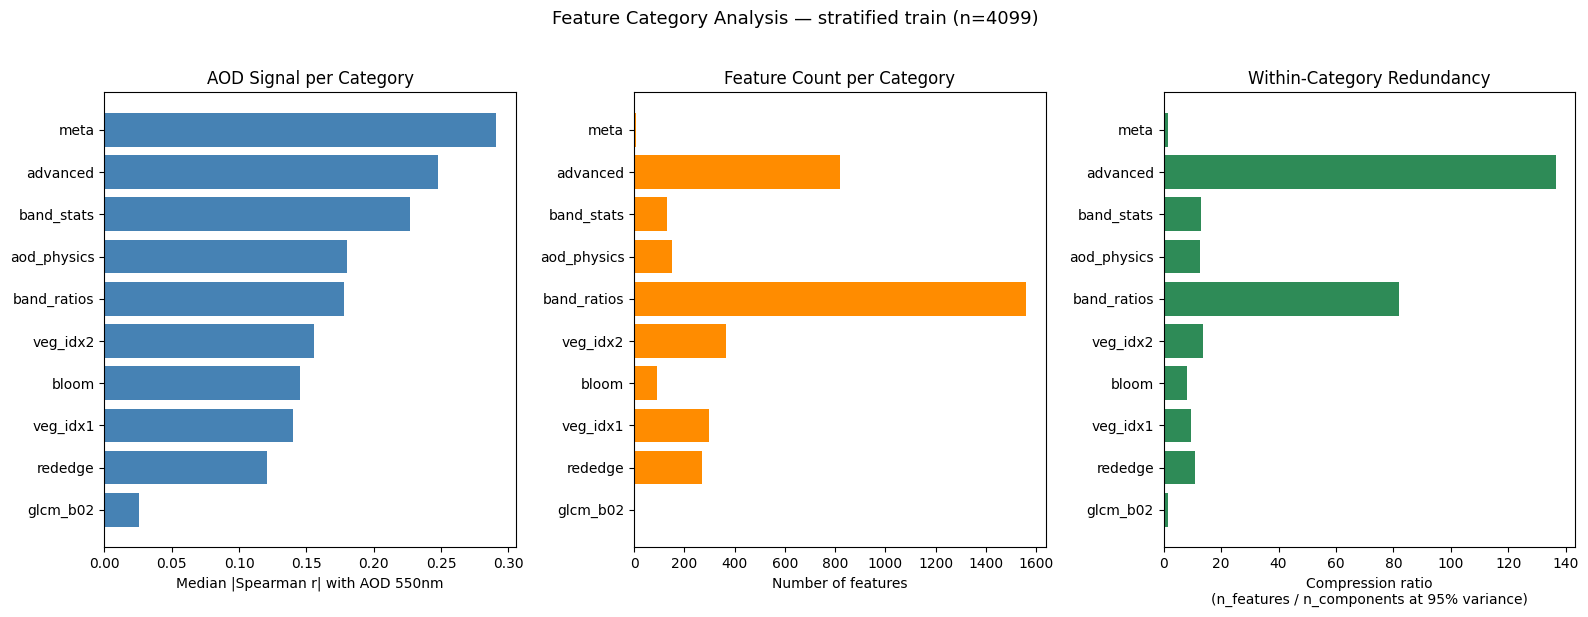

Saved: category_summary.png


In [6]:
merged = corr_df.join(pca_df[['n_components_95pct', 'compression_ratio']])
merged = merged.sort_values('median_abs_r', ascending=False)
cats   = merged.index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Panel 1: median |Spearman r| per category
axes[0].barh(cats, merged['median_abs_r'].values, color='steelblue')
axes[0].set_xlabel('Median |Spearman r| with AOD 550nm')
axes[0].set_title('AOD Signal per Category')
axes[0].invert_yaxis()

# Panel 2: feature count
axes[1].barh(cats, merged['n_features'].values, color='darkorange')
axes[1].set_xlabel('Number of features')
axes[1].set_title('Feature Count per Category')
axes[1].invert_yaxis()

# Panel 3: compression ratio (internal redundancy)
axes[2].barh(cats, merged['compression_ratio'].values, color='seagreen')
axes[2].set_xlabel('Compression ratio\n(n_features / n_components at 95% variance)')
axes[2].set_title('Within-Category Redundancy')
axes[2].invert_yaxis()

plt.suptitle('Feature Category Analysis — stratified train (n=4099)', y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(OUT / 'category_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: category_summary.png')

In [7]:
merged.to_csv(OUT / 'category_summary.csv')
print(f'Saved: category_summary.csv')
print(merged.to_string())

Saved: category_summary.csv
            n_features median_abs_r mean_abs_r max_abs_r             top_feature  n_components_95pct  compression_ratio
meta                 9        0.291     0.2159    0.4055  Site_Latitude(Degrees)                 6.0               1.50
advanced           819        0.248     0.2388    0.5673            cratio_1_8_9                 6.0             136.50
band_stats         130        0.227     0.2161    0.4914                 B02_p10                10.0              13.00
aod_physics        150       0.1802     0.1814    0.5184    aod_B01_over_B02_var                12.0              12.50
band_ratios       1560       0.1777     0.1911    0.5627         rdiff_9_12_mean                19.0              82.11
veg_idx2           368       0.1558     0.1728    0.5484                 wbi_p25                27.0              13.63
bloom               90       0.1455     0.1533    0.3176                PEBI_p90                11.0               8.18
veg_idx1    